# Paths, margin, and capital

`PortfolioEvolver` revalues the book along a path. It will not start while the forward curve is deterministic. This notebook builds the same pillars with `roll=sjd.ForwardRoll.FORWARD_VOLATILITY`, then compares an unmargined current-exposure portfolio with a margined one.

A spot path is the forward the book is marked against on each simulation date. Passing the curve's own forwards keeps the book on the expected forward. Monte Carlo then draws normal shocks around that curve. `sjd.stats` turns those paths into exposures, potential future exposure, CVA, DVA and regulatory capital.

`EE with HP` matches `EE` here. A holding-period (margin lag) offset is a separate evolver constructor and is not used in these notebooks.

`portfolio_validation.ipynb` is the preflight that fails before this forward is in place.

The path stops at the forward settlement. The Asian averaging month is still ahead of that date, so those days stay forwards rather than historic fixes. A rolled fixing curve only receives the simulation dates.


In [1]:
import math

import sjd
from sjd import examples

print(sjd.__file__)


E:\Code\sjd\python\sjd\__init__.py


## Stochastic market and two capital portfolios


In [2]:
market = examples.sample_market(stochastic=True)
assert market["forward"].is_ok(), market["forward"].error_messages()
environment = market["environment"]
credit = examples.credit_parameters()
factors = sjd.reg_cap_factors("commodity")

unmargined = sjd.PortfolioB2CEM(
    examples.sample_contracts(market["forward"], market)["contracts"],
    factors,
    credit,
    True,
)
agreement = sjd.SimpleMargin(
    market["anchor"],
    True,
    50_000.0,
    True,
    50_000.0,
    10_000.0,
    1_000.0,
)
margined = sjd.PortfolioB2CEM(
    examples.sample_contracts(market["forward"], market)["contracts"],
    factors,
    credit,
    True,
    agreement,
)
for portfolio in (unmargined, margined):
    report = portfolio.validate_report(environment)
    assert report.ok, [issue.message for issue in report.issues]

spot_path = [market["forward"].get_forward(day) for day in market["simulation_dates"]]
print("simulation dates", ", ".join(day.isoformat() for day in market["simulation_dates"]))
print("forward path", ", ".join(f"{spot:,.4f}" for spot in spot_path))


simulation dates 2026-09-16, 2026-12-17, 2027-03-16
forward path 17.5000, 17.6328, 17.7623


## Spot path

`value_spot_path` rolls the curves onto the simulation dates and marks the book there. The first row is the anchor mark-to-market. Regulatory capital is the current-exposure calculation in `sjd.stats`, using each trade's value on the path.


In [3]:
import numpy as np

from sjd import stats

def show_table(title, table):
    print(f"\n{title}")
    keys = [key for key in table if key != "dates"]
    print(f"{'Date':<12}" + "".join(f"{name:>14}" for name in keys))
    for index, day in enumerate(table["dates"]):
        print(f"{day:%Y-%m-%d}" + "".join(f"{table[key][index]:14,.2f}" for key in keys))

def forward_table(portfolio):
    evolver = sjd.PortfolioEvolver(
        portfolio,
        sjd.SingleFactorEconomicScenarioGenerator(environment),
        market["simulation_dates"],
    )
    report = evolver.validate_report()
    assert report.ok, [(issue.code, issue.message) for issue in report.issues]
    valued = evolver.value_spot_path(spot_path, by_structure=True)
    exposure = stats.exposure(valued)[0]
    table = {
        "dates": list(valued.dates),
        "spot": valued.spot[0],
        "mtm": valued.mtm[0],
        "ee": np.maximum(exposure, 0.0),
        "nee": np.minimum(exposure, 0.0),
        "reg_cap": stats.regulatory_capital(valued, portfolio.netting_sets(), factors, credit)[0],
    }
    if valued.margin is not None:
        table["margin"] = valued.margin[0]
    return table

plain_path = forward_table(unmargined)
collateral_path = forward_table(margined)
show_table("Unmargined forward path", plain_path)
show_table("Margined forward path", collateral_path)

anchor_mtm = unmargined.get_value(environment)
assert math.isclose(plain_path["mtm"][0], anchor_mtm, rel_tol=1e-8)
assert "margin" in collateral_path
assert "reg_cap" in plain_path



Unmargined forward path
Date                  spot           mtm            ee           nee       reg_cap
2026-09-16         17.50    410,941.59    410,941.59          0.00    376,664.68
2026-12-17         17.63    431,003.23    431,003.23          0.00    387,136.86
2027-03-16         17.76    438,422.94    438,422.94          0.00    248,221.30

Margined forward path
Date                  spot           mtm            ee           nee       reg_cap        margin
2026-09-16         17.50    410,941.59     49,941.59          0.00    347,784.68    361,000.00
2026-12-17         17.63    431,003.23     49,003.23          0.00    356,576.86    382,000.00
2027-03-16         17.76    438,422.94     56,422.94          0.00    217,661.30    382,000.00


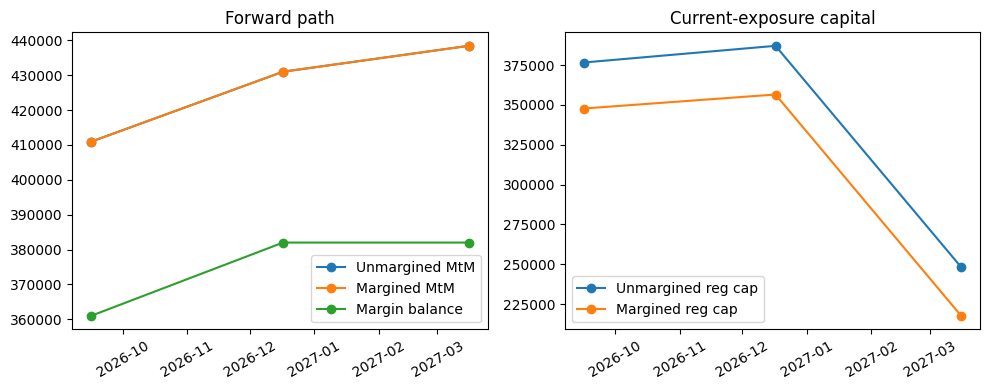

In [4]:
import matplotlib.pyplot as plt

dates = list(plain_path["dates"])
figure, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(dates, plain_path["mtm"], marker="o", label="Unmargined MtM")
axes[0].plot(dates, collateral_path["mtm"], marker="o", label="Margined MtM")
axes[0].plot(dates, collateral_path["margin"], marker="o", label="Margin balance")
axes[0].set_title("Forward path")
axes[0].legend()
axes[1].plot(dates, plain_path["reg_cap"], marker="o", label="Unmargined reg cap")
axes[1].plot(dates, collateral_path["reg_cap"], marker="o", label="Margined reg cap")
axes[1].set_title("Current-exposure capital")
axes[1].legend()
for axis in axes:
    axis.tick_params(axis="x", rotation=30)
figure.tight_layout()
plt.show()


## Monte Carlo

`sjd.simulate` draws antithetic pairs. `pfe` is the 95th percentile of positive exposure and `negative_pfe` is the 5th percentile of negative exposure. Fifty paths are enough to see the shape; they are not a production confidence interval.

Both books use `SEED`, so the output is reproducible and the two books see the same shocks. The gap between them comes from margin. CVA and DVA discount the expected exposure with a flat 1% default probability and a 60% loss given default.

The margined book's expected exposure is the positive part of `MtM - margin balance`, so it sits below the unmargined expected exposure once collateral has caught up.



Unmargined Monte Carlo
Date                  spot           mtm            ee           nee           pfe  negative_pfeee_standard_error       reg_cap
2026-09-16         17.50    410,941.59    410,941.59          0.00    410,941.59          0.00          0.00    376,664.68
2026-12-17         17.63    415,956.34    636,385.99   -220,429.65  1,794,434.97   -890,478.76     40,080.58    294,306.47
2027-03-16         17.77    448,197.10  1,234,008.72   -785,811.62  4,340,612.25 -3,127,757.92    134,131.39    256,528.95

Margined Monte Carlo
Date                  spot           mtm        margin            ee           nee           pfe  negative_pfeee_standard_error       reg_cap
2026-09-16         17.50    410,941.59    361,000.00     49,941.59          0.00     49,941.59          0.00          0.00    347,784.68
2026-12-17         17.63    415,956.34    408,960.00     27,745.99    -20,749.65     49,949.42    -49,728.16      1,644.56    245,615.27
2027-03-16         17.77    448,197.10   

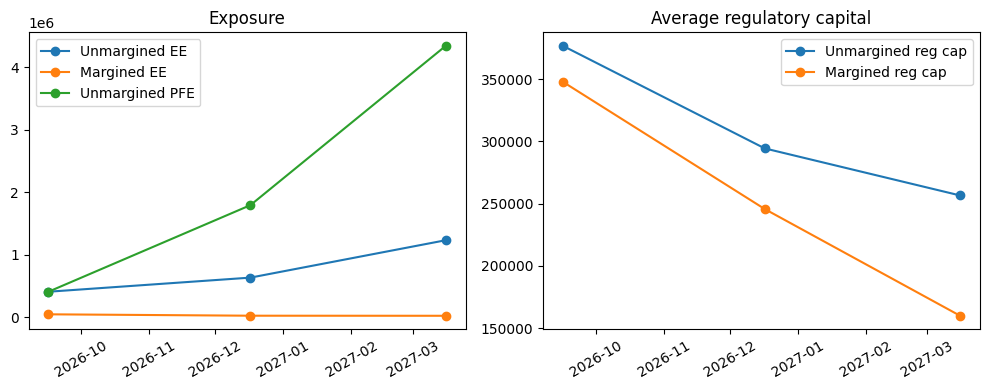

In [5]:
import matplotlib.pyplot as plt

SEED = 2026

def monte_carlo(portfolio):
    simulation = sjd.simulate(
        portfolio,
        environment,
        market["simulation_dates"],
        paths=50,
        seed=SEED,
        by_structure=True,
    )
    table = stats.summary(simulation)
    table["reg_cap"] = stats.regulatory_capital(
        simulation, portfolio.netting_sets(), factors, credit
    ).mean(axis=0)
    return table

plain_mc = monte_carlo(unmargined)
collateral_mc = monte_carlo(margined)
show_table("Unmargined Monte Carlo", plain_mc)
show_table("Margined Monte Carlo", collateral_mc)
assert "pfe" in plain_mc
assert "margin" in collateral_mc

discount = [market["discount"].get_discount_factor(day) for day in plain_mc["dates"]]
probability = stats.flat_default_probability(market["anchor"], plain_mc["dates"], 0.01)
loss = [0.6] * len(plain_mc["dates"])
print("Unmargined CVA", f"{stats.credit_valuation_adjustment(plain_mc['ee'], discount, probability, loss):,.2f}")
print("Unmargined DVA", f"{stats.debit_valuation_adjustment(plain_mc['nee'], discount, probability, loss):,.2f}")
print("Margined CVA", f"{stats.credit_valuation_adjustment(collateral_mc['ee'], discount, probability, loss):,.2f}")

dates = list(plain_mc["dates"])
figure, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(dates, plain_mc["ee"], marker="o", label="Unmargined EE")
axes[0].plot(dates, collateral_mc["ee"], marker="o", label="Margined EE")
axes[0].plot(dates, plain_mc["pfe"], marker="o", label="Unmargined PFE")
axes[0].set_title("Exposure")
axes[0].legend()
axes[1].plot(dates, plain_mc["reg_cap"], marker="o", label="Unmargined reg cap")
axes[1].plot(dates, collateral_mc["reg_cap"], marker="o", label="Margined reg cap")
axes[1].set_title("Average regulatory capital")
axes[1].legend()
for axis in axes:
    axis.tick_params(axis="x", rotation=30)
figure.tight_layout()
plt.show()
